# 05 · Long-term reservoir simulation

$$V(t+1) = V(t) + Q_{in} - Q_e - E - Q_s - Q_{spill}, \qquad V_{min} \le V \le V_{max}$$

Each month: (1) add the inflow, (2) release the e-flow $Q_e = \min(Q_{e,target}, Q_{in})$ with
$Q_{e,target}(m) = 0.10 \cdot \overline{Q_{in}}(m)$, (3) evaporation $E = PET \cdot A / 1000$ (hm³, never
below $V_{min}$), (4) supply $Q_s = \min(D, V - V_{min})$, (5) spill above $V_{max}$. Start full.

First with a fixed area $A_0$, then with $A(h) = dV/dh$ from the h–V curve.

In [1]:
%load_ext autoreload
%autoreload 2               
import sys, json
from pathlib import Path
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data")
PROC = DATA / "processed"
PROC.mkdir(exist_ok=True)
case = json.loads((DATA / "case.json").read_text())
case

{'catchment_area_km2': 55.33,
 'latitude_deg': 38.237,
 'longitude_deg': -7.687,
 'smax_mm': 100,
 'hmax_m': 5.0,
 'hmin_m': 1.0,
 'area_fixed_km2': 0.0685,
 'irrigation_months': [6, 7, 8, 9],
 'demand_hm3_per_month': 0.02,
 'eflow_fraction': 0.1,
 'target_reliability': 0.9}

In [2]:
from epss.eflows import eflow_targets
from epss.reservoir import Reservoir

cat = pd.read_csv(PROC / "catchment.csv", index_col=0, parse_dates=True)

cat = cat.dropna(subset=["inflow", "pet"])

inflow, evap = cat.inflow, cat.pet
hv = pd.read_csv(DATA / "hv_curve.csv")

Demand: $D$ in the irrigation months, 0 otherwise. E-flow targets by calendar month.

In [3]:
# TODO: Demand series: case['demand_hm3_per_month'] in the irrigation months
#       (case['irrigation_months']), 0 otherwise.
# In: inflow.index, case
# Out: demand (pd.Series, hm³/month)
demand = pd.Series(
    np.where(inflow.index.month.isin(case["irrigation_months"]),
             case["demand_hm3_per_month"], 0.0),
    index=inflow.index
)
eflow = eflow_targets(inflow, case["eflow_fraction"])
pd.DataFrame({"inflow": inflow, "eflow target": eflow, "demand": demand}).groupby(inflow.index.month).mean().round(4)

,inflow,eflow target,demand
1,1.0071,0.1007,0.00
2,0.6263,0.0626,0.00
3,0.3641,0.0364,0.00
4,0.0815,0.0082,0.00
5,0.0000,0.0000,0.00
6,0.0000,0.0000,0.02
7,0.0000,0.0000,0.02
8,0.0000,0.0000,0.02
9,0.0000,0.0000,0.02
10,0.0000,0.0000,0.00


## h–V and h–A curves

Vmax = 0.252 hm³, Vmin = 0.0045 hm³


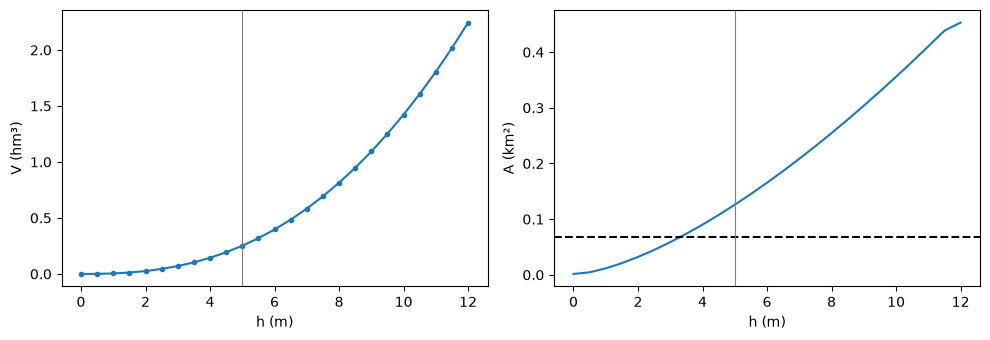

In [4]:
res_var = Reservoir(hv, case["hmax_m"], case["hmin_m"])
h = np.linspace(0, hv.h_m.max(), 100)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hv.h_m, hv.v_hm3, "o-", ms=3); ax[0].set_xlabel("h (m)"); ax[0].set_ylabel("V (hm³)")
ax[1].plot(h, [res_var.area(res_var.volume(x)) for x in h]); ax[1].axhline(case["area_fixed_km2"], ls="--", c="k")
ax[1].set_xlabel("h (m)"); ax[1].set_ylabel("A (km²)")
for a in ax: a.axvline(case["hmax_m"], c="grey", lw=0.8)
plt.tight_layout()
print(f"Vmax = {res_var.vmax:.3f} hm³, Vmin = {res_var.vmin:.4f} hm³")

## Fixed surface area $A_0$

In [5]:
res_fix = Reservoir(hv, case["hmax_m"], case["hmin_m"], area=case["area_fixed_km2"])
sim_fix = res_fix.simulate(inflow, evap, demand, eflow)
sim_fix.head(12).round(4)

,inflow,eflow,evaporation,supply,deficit,spill,volume,level
1981-01-01,0.0000,0.0000,0.0030,0.00,0.0,0.0000,0.2486,4.9745
1981-02-01,0.3357,0.0626,0.0035,0.00,0.0,0.2666,0.2516,5.0000
1981-03-01,0.0000,0.0000,0.0055,0.00,0.0,0.0000,0.2460,4.9524
1981-04-01,0.3437,0.0082,0.0061,0.00,0.0,0.3239,0.2516,5.0000
1981-05-01,0.0000,0.0000,0.0088,0.00,0.0,0.0000,0.2428,4.9245
1981-06-01,0.0000,0.0000,0.0124,0.02,0.0,0.0000,0.2104,4.6467
1981-07-01,0.0000,0.0000,0.0136,0.02,0.0,0.0000,0.1768,4.3326
1981-08-01,0.0000,0.0000,0.0117,0.02,0.0,0.0000,0.1451,4.0116
1981-09-01,0.0000,0.0000,0.0080,0.02,0.0,0.0000,0.1171,3.6714
1981-10-01,0.0000,0.0000,0.0055,0.00,0.0,0.0000,0.1117,3.6047


Conservation of mass over the whole simulation: $V_{end} - V_0 = \sum(Q_{in} - Q_e - E - Q_s - Q_{spill})$.

In [6]:
# TODO: Mass balance over the whole simulation: (V_end - V0) - sum(Qin - Qe - E - Qs - Qspill),
#       with V0 = Vmax.
# In: sim_fix, res_fix.vmax
# Out: out (hm³, sum of all outflows), error (hm³)
out = sim_fix[["eflow", "evaporation", "supply", "spill"]].sum().sum()

error = (sim_fix["volume"].iloc[-1] - res_fix.vmax) - (sim_fix["inflow"].sum() - out)
print(f"Mass balance error: {error:.2e} hm³")
sim_fix[["inflow", "eflow", "evaporation", "supply", "spill", "deficit"]].sum().round(3)

Mass balance error: 4.72e-15 hm³


inflow         163.859
eflow            5.444
evaporation      2.672
supply           2.451
spill          153.540
deficit          0.749
dtype: float64

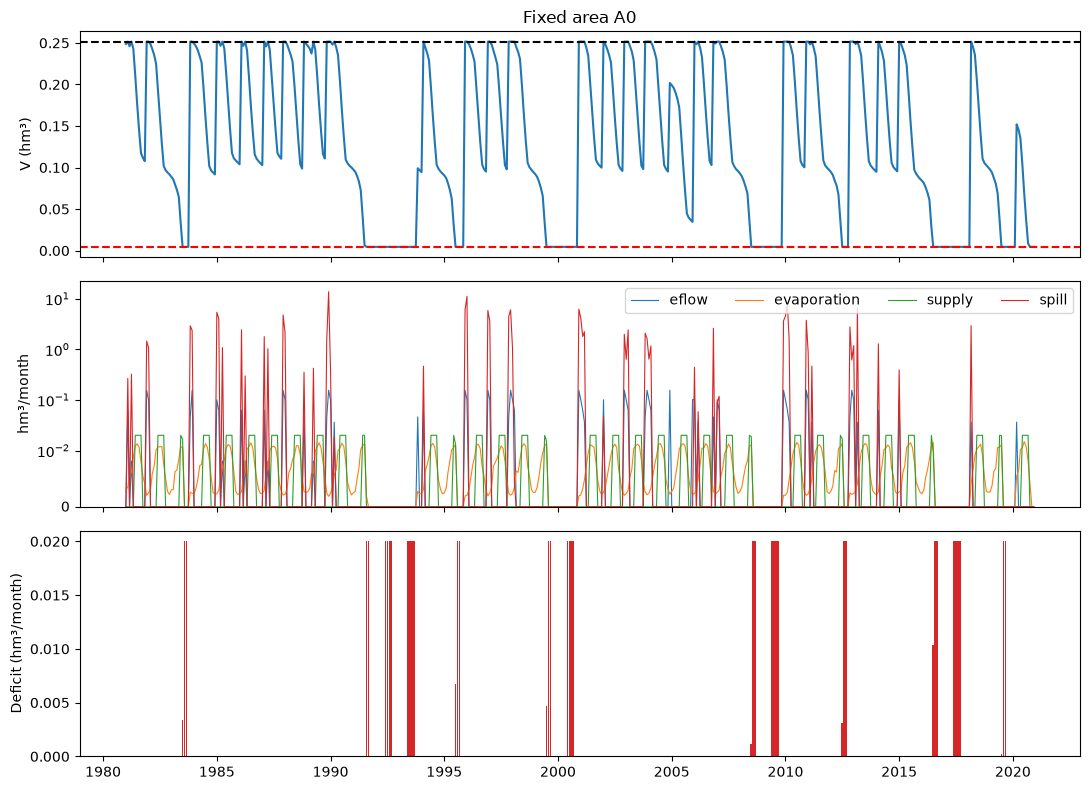

In [7]:
def plot_sim(sim, res, title):
    fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    ax[0].plot(sim.index, sim.volume); ax[0].axhline(res.vmax, c="k", ls="--"); ax[0].axhline(res.vmin, c="r", ls="--")
    ax[0].set_ylabel("V (hm³)"); ax[0].set_title(title)
    for col in ["eflow", "evaporation", "supply", "spill"]:
        ax[1].plot(sim.index, sim[col], lw=0.8, label=col)
    ax[1].set_yscale("symlog", linthresh=0.01); ax[1].set_ylim(0, None)
    ax[1].set_ylabel("hm³/month"); ax[1].legend(ncol=4)
    ax[2].bar(sim.index, sim.deficit, width=25, color="tab:red"); ax[2].set_ylabel("Deficit (hm³/month)")
    plt.tight_layout()

plot_sim(sim_fix, res_fix, "Fixed area A0")

In [8]:
# TODO: Critical periods: months with deficit, grouped by year, with their count and total
#       deficit.
# In: sim_fix
# Out: fail (rows with deficit > 0), critical (DataFrame by year with columns count, sum)
fail = sim_fix[sim_fix["deficit"] > 0]

critical = fail.groupby(fail.index.year)["deficit"].agg(["count", "sum"])
critical.rename(columns={"count": "months with deficit", "sum": "deficit (hm³)"}).round(3)

,months with deficit,deficit (hm³)
1983,3,0.043
1991,2,0.040
1992,4,0.080
1993,4,0.080
1995,3,0.047
1999,3,0.045
2000,4,0.080
2008,3,0.041
2009,4,0.080
2012,3,0.043


## Surface area from the h–V curve, $A(h) = dV/dh$

,fixed A0,A(h)
evaporation,2.672,3.426
supply,2.451,2.362
deficit,0.749,0.838
spill,153.540,152.870
mean level (m),3.431,3.202


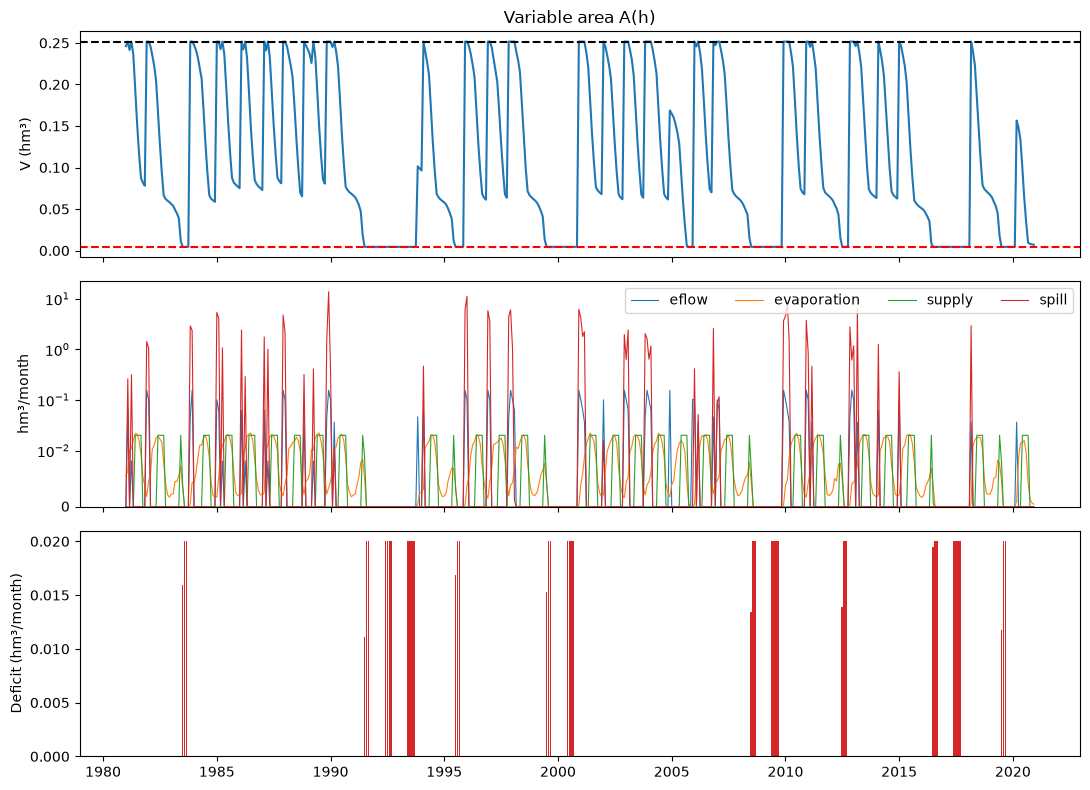

In [9]:
sim_var = res_var.simulate(inflow, evap, demand, eflow)
plot_sim(sim_var, res_var, "Variable area A(h)")
compare = pd.DataFrame({"fixed A0": sim_fix[["evaporation", "supply", "deficit", "spill"]].sum(),
                        "A(h)": sim_var[["evaporation", "supply", "deficit", "spill"]].sum()})
compare.loc["mean level (m)"] = [sim_fix.level.mean(), sim_var.level.mean()]
compare.round(3)

**Answer.**

The results show that the reservoir fills during wet periods and loses water during dry months due to evaporation and irrigation demand.

Comparing the two models, the variable surface area A(h) results in higher total evaporation (3.426 hm³ compared to 2.672 hm³ with fixed area) and a higher water supply deficit (0.838 hm³ compared to 0.749 hm³).

The variable-area model also produces a lower mean reservoir level, decreasing from 3.431 m to 3.202 m.

The mass balance error is practically zero, indicating that the model conserves water. However, some months have water supply deficits, showing that the reservoir cannot always meet irrigation demand.